# Playbook · Free S&P 500 financial statements in Python

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/valuein/valuein/blob/main/examples/playbooks/free-sp500-statements.ipynb)

**Who it is for:** students, analysts and builders who want clean statements for S&P 500 companies without paying or signing up.

**What you get:** income statement, balance sheet and cash flow for any S&P 500 company, current or former, from SEC filings, a chart, and a CSV with the source of every number.

**Plan needed:** none. No API key, no account, no card. The free sample covers S&P 500 companies, including former members, for the last five years.

## Step 1 · Install and connect

One package, no key. Passing `api_key=""` forces the free sample even if a key sits in your environment.

In [1]:
%pip install -q "valuein-sdk>=1.1.0" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from valuein_sdk import ValueinClient

warnings.filterwarnings("ignore", message="Defaulting to SAMPLE dataset")
client = ValueinClient(api_key="")
print("plan:", client.plan)

Using the free sample means accepting the Valuein Data Licence: valuein.biz/terms#data-licence


plan: sample


### Pick a company

Resolve a ticker, or a few, to the CIK. A company that has left the index is still there.

In [3]:
TICKER = "KO"
company = client.resolve(TICKER).iloc[0]
print(company["name"], "| CIK", company["cik"])

COCA COLA CO | CIK 0000021344


**Check it worked:** it prints `plan: sample`.

Then: a company name and its 10-digit CIK.

## Step 2 · Income statement

Five fiscal years as known today, USD, one column per period end.

In [4]:
fin = client.financials(TICKER, periods=5)
(fin.income / 1e9).round(2).head(12)

period_end,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31
concept,,,,,
TotalRevenue,38.66,43.00,45.75,47.06,47.94
CostOfRevenue,15.36,18.00,18.52,18.32,18.40
DepreciationAndAmortization,1.45,1.26,1.13,1.08,1.05
GrossProfit,23.30,25.00,27.23,28.74,29.54
SellingGeneralAdmin,12.14,12.88,13.97,14.58,14.52
OperatingIncome,10.31,10.91,11.31,9.99,13.76
InterestExpense,1.60,0.88,1.53,1.66,1.65
PretaxIncome,12.42,11.69,12.95,13.09,16.00
IncomeTaxExpense,2.62,2.12,2.25,2.44,2.86


### Balance sheet

What the company owned and owed at each period end.

In [5]:
(fin.balance / 1e9).round(2).head(12)

period_end,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31
concept,,,,,
CashAndEquivalents,9.68,9.52,9.37,10.83,10.27
ShortTermInvestments,10.93,10.56,12.36,12.85,13.87
AccountsReceivable,3.51,3.49,3.41,3.57,3.04
Inventory,3.41,4.23,4.42,4.73,4.42
CurrentAssets,22.54,22.59,26.73,26.00,31.04
PPENet,9.92,9.84,9.24,10.30,9.61
Goodwill,19.36,18.78,18.36,18.14,15.49
TotalAssets,94.35,92.76,97.70,100.55,104.82
ShortTermDebt,2.46,2.15,4.21,1.14,1.50


### Cash flow

Annual cash flow statements. Capital expenditure is shown as the filing reports it.

In [6]:
(fin.cash_flow / 1e9).round(2).head(12)

period_end,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31
concept,,,,,
OperatingCashFlow,12.62,11.02,11.60,6.80,7.41
StockBasedCompensation,0.34,0.36,0.25,0.29,0.28
CAPEX,1.37,1.48,1.85,2.06,2.11
InvestingCashFlow,-2.76,-0.76,-3.35,2.52,-0.07
Dividends,7.25,7.62,7.95,8.36,8.78
ShareBuyback,0.11,1.42,2.29,1.80,0.75
FinancingCashFlow,-6.79,-10.25,-8.31,-6.91,-8.14
NetChangeInCash,2.92,-0.20,-0.13,1.80,-0.48
AccountsPayableChange,2.84,0.76,0.84,1.13,-6.61


**Check it worked:** a table of income lines in USD billions with five columns.

Then: a table of balance sheet lines in USD billions.

Then: a table of cash flow lines in USD billions.

## Step 3 · Chart it

Revenue, operating income and net income, straight from the statements above.

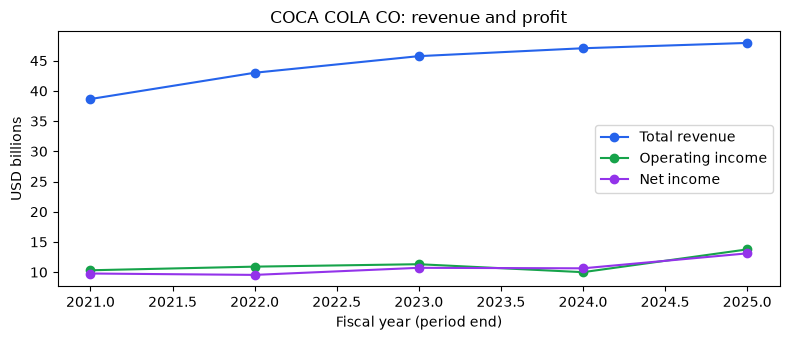

In [7]:
years = [d.year for d in fin.income.columns]
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, concept, color in [("Total revenue", "TotalRevenue", "#2563eb"),
                              ("Operating income", "OperatingIncome", "#16a34a"),
                              ("Net income", "NetIncome", "#9333ea")]:
    if concept in fin.income.index:
        ax.plot(years, fin.income.loc[concept] / 1e9, marker="o", label=label, color=color)
ax.set_xlabel("Fiscal year (period end)")
ax.set_ylabel("USD billions")
ax.set_title(f"{company['name']}: revenue and profit")
ax.legend()
plt.tight_layout()
plt.show()

**Check it worked:** a line chart with five points per line.

## Step 4 · Export with sources

A CSV in which every number keeps the `fact_id` and the filing it came from.

In [8]:
sourced = (fin.lineage[["statement", "concept", "period_end", "value", "unit", "form_type",
                        "accession_id", "accepted_at", "fact_id"]]
           .sort_values(["statement", "concept", "period_end"]))
path = f"{TICKER.lower()}_statements.csv"
sourced.to_csv(path, index=False)
print(len(sourced), "numbers written to", path)
client.close()

607 numbers written to ko_statements.csv


**Check it worked:** a CSV with one row per number and its filing and `fact_id`.

**Next:** [Cover a company](cover-a-company.ipynb) · [Quickstart](../notebooks/01_quickstart.ipynb) · [Backtest without bias](backtest-without-bias.ipynb)

Every S&P 500 member since 1996, including former members, is in the data; the free sample shows the last five years. More history: a free Benchmark key at https://valuein.biz/signup/free.

_Index names are trademarks of their owners; Valuein is not affiliated with or endorsed by any index provider._